# 02. Financial values and outliers

**The question this notebook answers:** money fields have a few enormous values. How do we describe them honestly, separate real extremes from mistakes, and prepare them so one freak value cannot dominate a model?

The brief calls this *"a core part of the assessment"* and it carries the most points in Part A (20). It asks, **for each financial field**:

1. Describe the distribution (mean, median, standard deviation, IQR, skewness, percentiles p1 to p99) and plot it on a linear **and** a log scale.
2. Explain whether *mean ± 3 standard deviations* is a sound outlier rule, and why or why not.
3. Separate **errors** (impossible values, unit mistakes) from **genuine extremes** (a real high earner, utilisation above 100% after a limit cut), and treat them differently.
4. Choose and justify an outlier method, and show its effect on the distribution and on default rate by decile, before and after.
5. Handle zero, negative and missing amounts explicitly (a zero balance is not a balance that was never recorded).
6. Compute every cap and statistic on loans up to the fit cutoff only, and store them in `data_spec.json`.

The fields: `annual_inc`, `loan_amnt`, `installment`, `revol_bal`, `tot_cur_bal`, `avg_cur_bal`, `total_rev_hi_lim`, `tot_hi_cred_lim`, plus the ratios `dti`, `revol_util`, `bc_util`.

In [1]:
import os, json
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from credit_risk.io import FIT_CUTOFF, load_applications
from credit_risk.cleaning import Cleaner
from credit_risk.outliers import AmountTreater

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

joined = load_applications()                                   # applications + bureau, one row per loan
clean = Cleaner().fit(joined).transform(joined)               # unit errors repaired (notebook 01)
fit = clean[clean.issue_d <= FIT_CUTOFF]                      # the loans allowed to teach the rules (up to 31 Dec 2014)

MONEY = ["annual_inc", "loan_amnt", "installment", "revol_bal", "tot_cur_bal", "avg_cur_bal", "total_rev_hi_lim", "tot_hi_cred_lim"]
RATIOS = ["dti", "revol_util", "bc_util"]
print(f"{len(clean):,} loans in total; {len(fit):,} in the fit window (to {FIT_CUTOFF.date()}). Every statistic below uses the fit window only.")

30,000 loans in total; 14,373 in the fit window (to 2014-12-31). Every statistic below uses the fit window only.


## Worked example: ten incomes

Ten applicants' incomes, in thousands of dollars: nine ordinary people and one who earns a million.

In [2]:
x = pd.Series([40, 45, 50, 52, 55, 58, 60, 62, 65, 1000.0])
q1, q3 = x.quantile([0.25, 0.75])
med = x.median()
mad = (x - med).abs().median()
toy = pd.Series({
    "mean (add up, divide by 10)": x.mean(),
    "median (the middle value)": med,
    "standard deviation": x.std(ddof=0),
    "Q1 (25th percentile)": q1, "Q3 (75th percentile)": q3,
    "IQR = Q3 - Q1": q3 - q1,
    "mean + 3 std  (the 'classic' upper fence)": x.mean() + 3 * x.std(ddof=0),
    "mean - 3 std": x.mean() - 3 * x.std(ddof=0),
    "z-score of the millionaire": (1000 - x.mean()) / x.std(ddof=0),
    "IQR upper fence = Q3 + 1.5 x IQR": q3 + 1.5 * (q3 - q1),
})
print(toy.round(1).to_string())

mean (add up, divide by 10)                   148.7
median (the middle value)                      56.5
standard deviation                            283.9
Q1 (25th percentile)                           50.5
Q3 (75th percentile)                           61.5
IQR = Q3 - Q1                                  11.0
mean + 3 std  (the 'classic' upper fence)    1000.3
mean - 3 std                                 -702.9
z-score of the millionaire                      3.0
IQR upper fence = Q3 + 1.5 x IQR               78.0


**Reading it.**
- One person pulled the **mean** (148.7) far above all nine ordinary people, while the **median** (56.5) barely noticed. The **standard deviation** (284) was inflated by the same person.
- The classic rule says "flag anything above mean + 3 standard deviations". That fence is **1000.3**, and the millionaire earns **1000**, so the rule says *"not an outlier"*. The lower fence is **negative** (-703), which no income can reach, so it can never flag anything.
- **Why it fails:** the standard deviation is calculated *using* the outlier, so the outlier stretches the very ruler used to measure it.
- A rule built on percentiles (the **IQR fence**, 78) does flag the millionaire, because Q1 and Q3 ignore the extremes.

Now the same thing on real data.

## 1. Describe each field (bullet 1)

Mean, median, standard deviation, IQR, skewness and the percentiles the brief lists, for all 11 fields, on the fit window.

**Skewness** is one number for "how lopsided": 0 is symmetric, large and positive means a long tail of huge values on the right.

In [3]:
def profile(s):
    s = s.dropna()
    p = s.quantile([.01, .05, .25, .5, .75, .95, .99])
    return pd.Series({"n": len(s), "mean": s.mean(), "median": s.median(), "std": s.std(), "iqr": p[.75] - p[.25], "skew": s.skew(),
                      "p1": p[.01], "p5": p[.05], "p25": p[.25], "p50": p[.5], "p75": p[.75], "p95": p[.95], "p99": p[.99],
                      "min": s.min(), "max": s.max(), "zeros_%": 100 * (s == 0).mean()})
table = pd.DataFrame({f: profile(fit[f]) for f in MONEY + RATIOS}).T
table[["n", "skew", "zeros_%"]] = table[["n", "skew", "zeros_%"]].round(2)
print(table.drop(columns=["n"]).round(1).to_string())

                      mean    median       std       iqr  skew       p1       p5      p25       p50       p75       p95       p99     min        max  zeros_%
annual_inc         74374.3   64900.0   76972.6   45000.0  63.3  19620.2  29000.0  45000.0   64900.0   90000.0  150000.0  250000.0  7500.0  7500000.0      0.0
loan_amnt          14635.7   12975.0    8328.1   12000.0   0.7   1736.0   3700.0   8000.0   12975.0   20000.0   31100.0   35000.0  1000.0    35000.0      0.0
installment          444.8     388.1     246.4     314.5   0.9     59.2    125.9    268.6     388.1     583.1     931.2    1195.9    23.3     1406.4      0.0
revol_bal          16517.3   11965.0   20230.1   13861.0   8.3    556.4   2389.4   6532.0   11965.0   20393.0   41060.2   88339.3     0.0   624356.0      0.3
tot_cur_bal       138834.1   80428.0  152176.3  181986.0   2.9   3309.9   8506.4  28460.0   80428.0  210446.0  418800.6  631213.2     0.0  3370799.0      0.0
avg_cur_bal        13446.8    7554.0   16086.6   159

**Reading it.** For `annual_inc`, the mean (about $74,000) sits well above the median (about $65,000), the standard deviation is larger than the IQR, the maximum is $7.5 million against a 99th percentile of $250,000, and the skewness is 63. That is a long right tail. The ratios (`dti`, `revol_util`, `bc_util`) are nearly symmetric (skewness near 0), so they behave very differently from the money fields.

### Plots: linear scale and log scale

On a linear scale a few huge values squash everyone else into one bar. On a **log scale** each step is "ten times bigger" and the same data spreads out into the shape most people expect. We draw both for `annual_inc` and `revol_bal` live, and show every field's pair below.

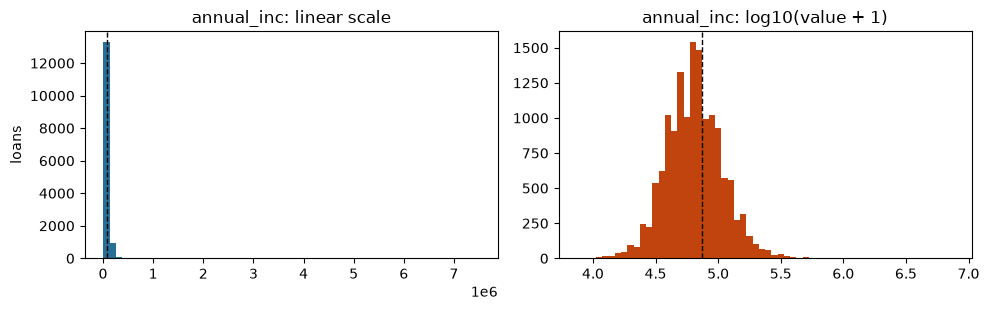

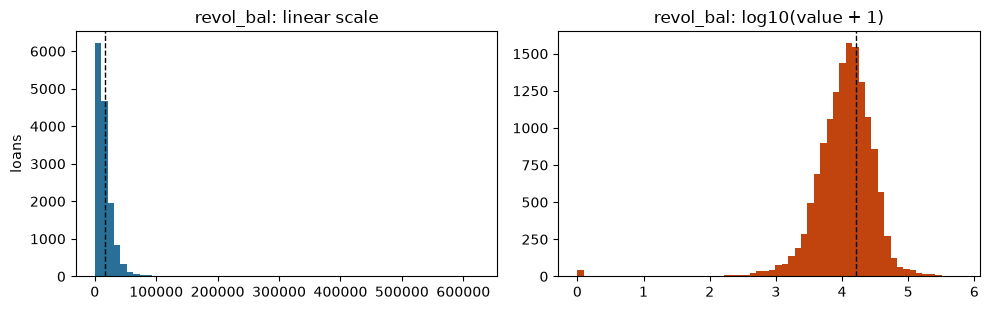

In [4]:
def two_scales(field):
    x = fit[field].dropna()
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
    ax[0].hist(x, bins=60, color="#2a6f97"); ax[0].set_title(f"{field}: linear scale"); ax[0].axvline(x.mean(), color="k", ls="--", lw=1)
    ax[1].hist(np.log10(x + 1), bins=60, color="#c1440e"); ax[1].set_title(f"{field}: log10(value + 1)"); ax[1].axvline(np.log10(x.mean() + 1), color="k", ls="--", lw=1)
    ax[0].set_ylabel("loans"); fig.tight_layout(); plt.show()
two_scales("annual_inc"); two_scales("revol_bal")

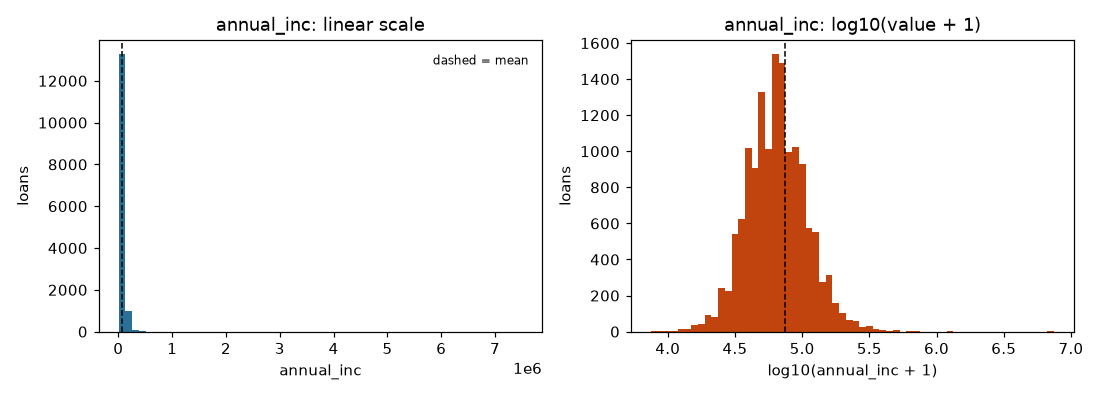

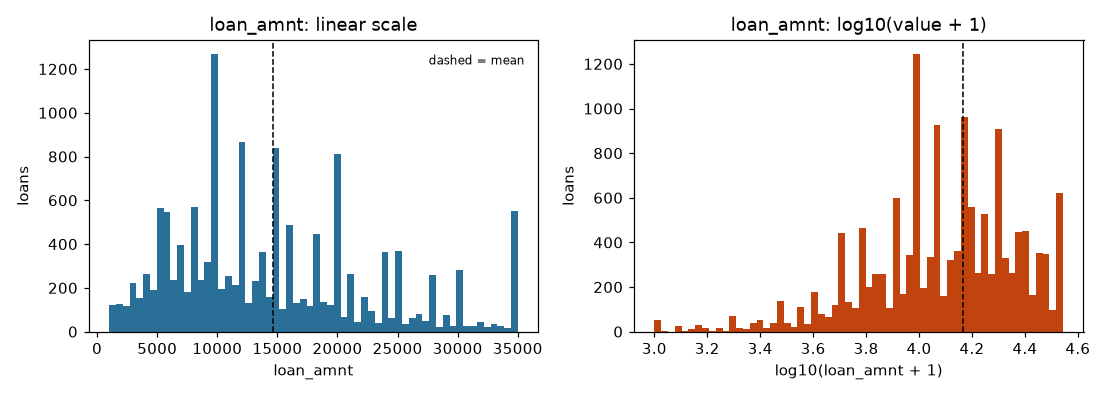

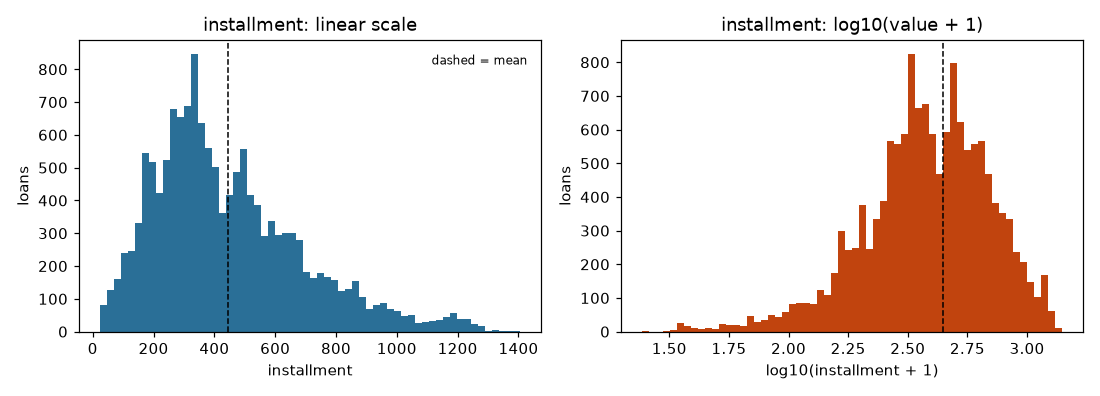

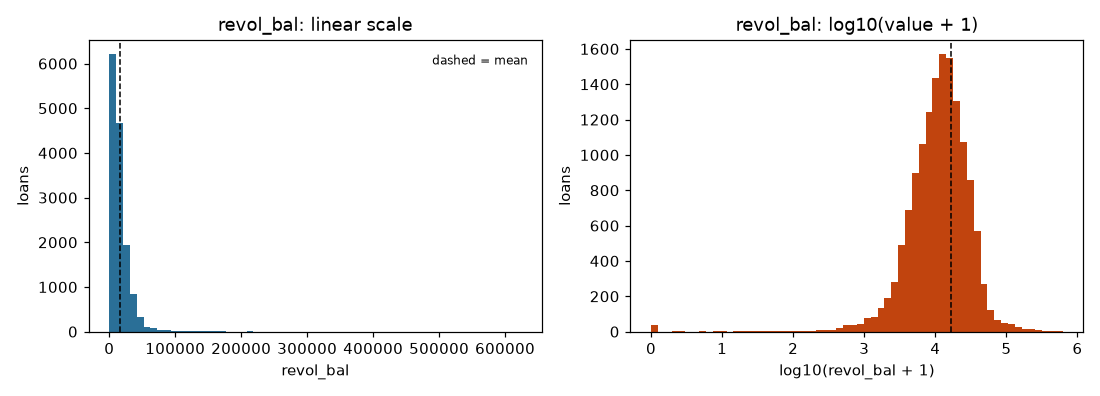

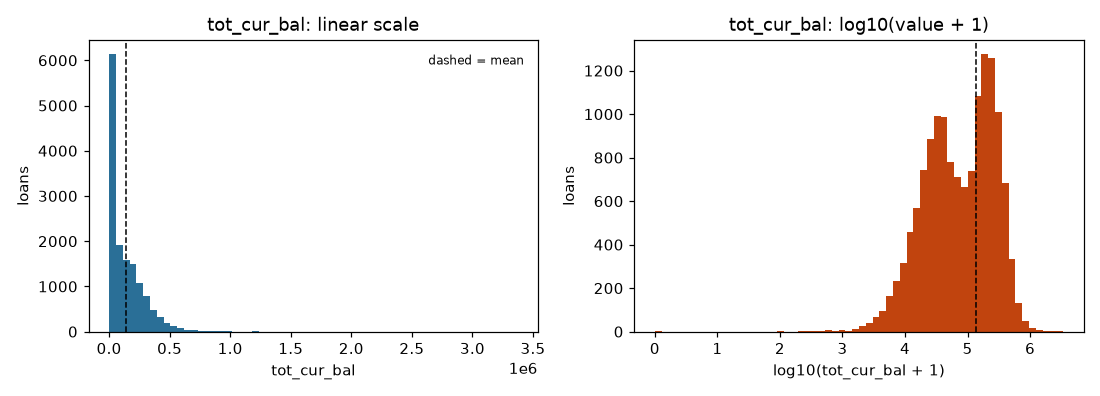

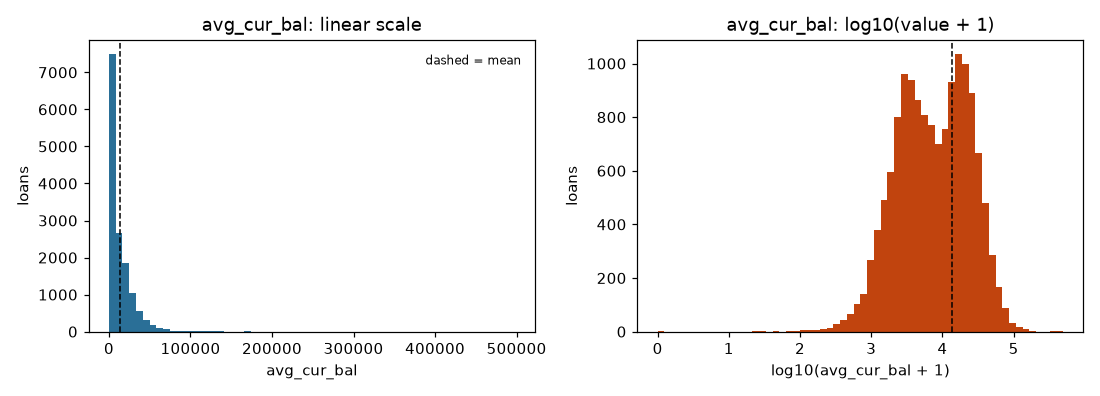

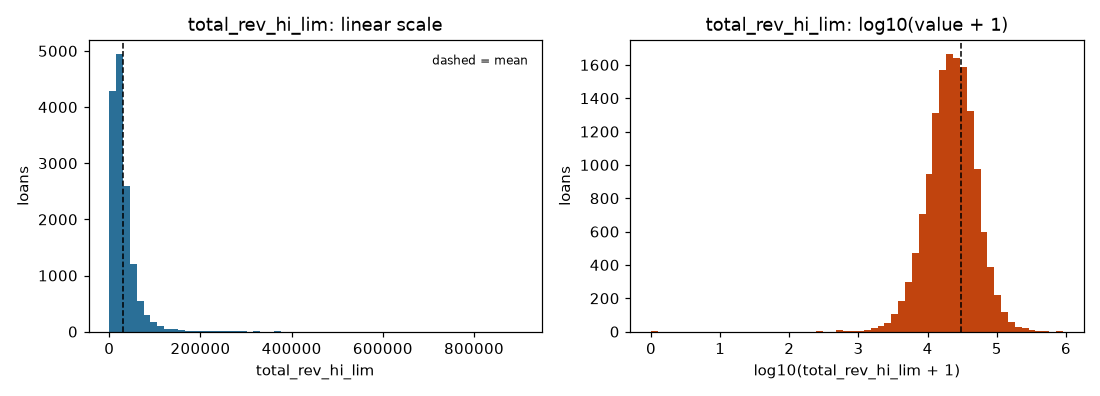

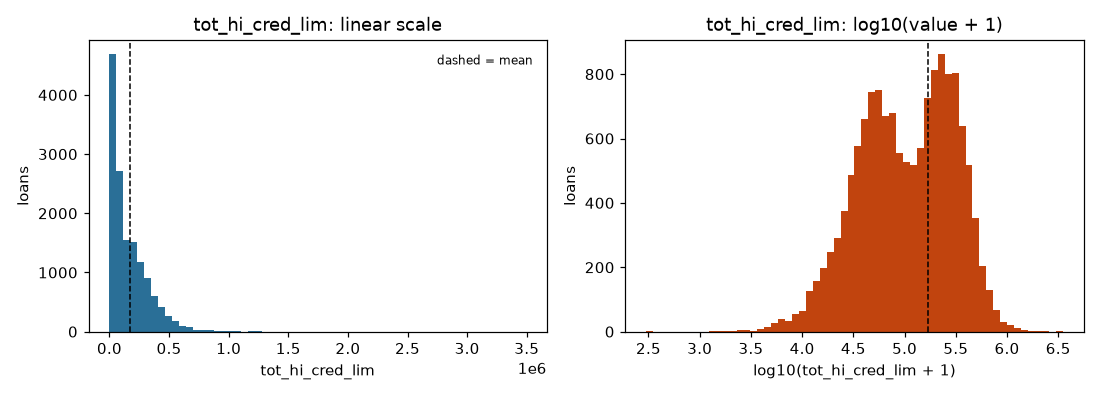

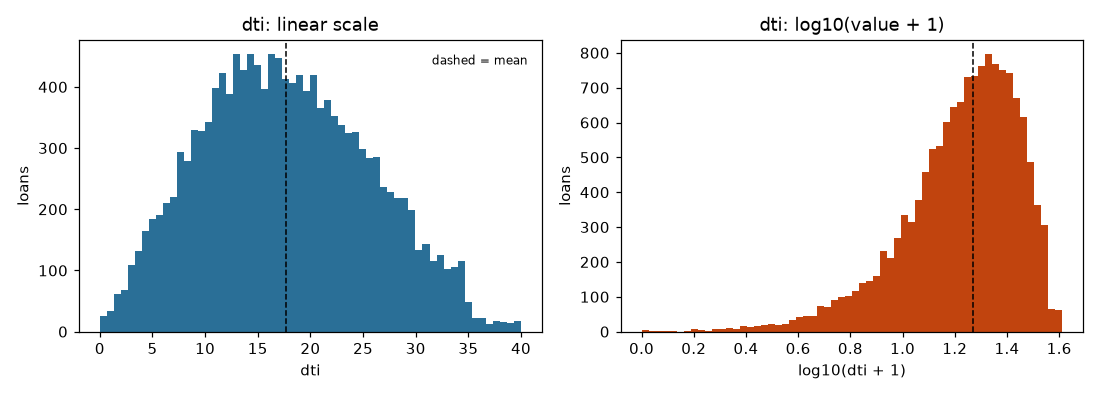

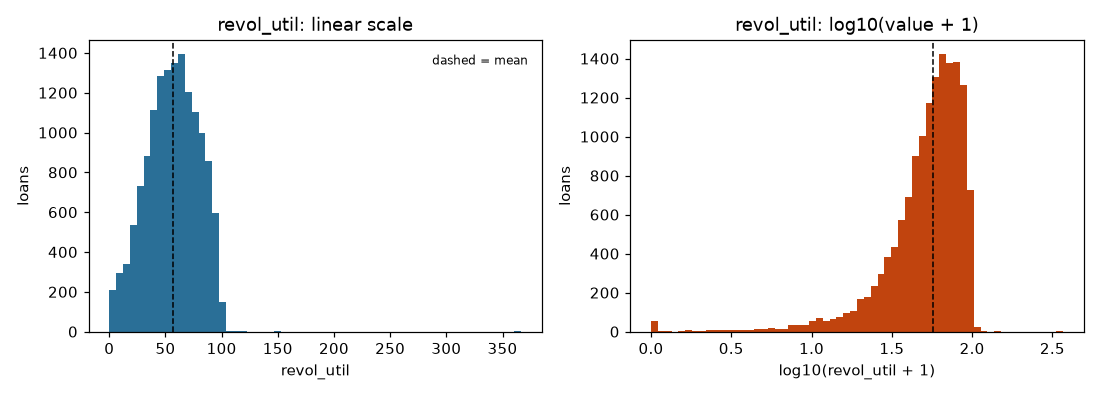

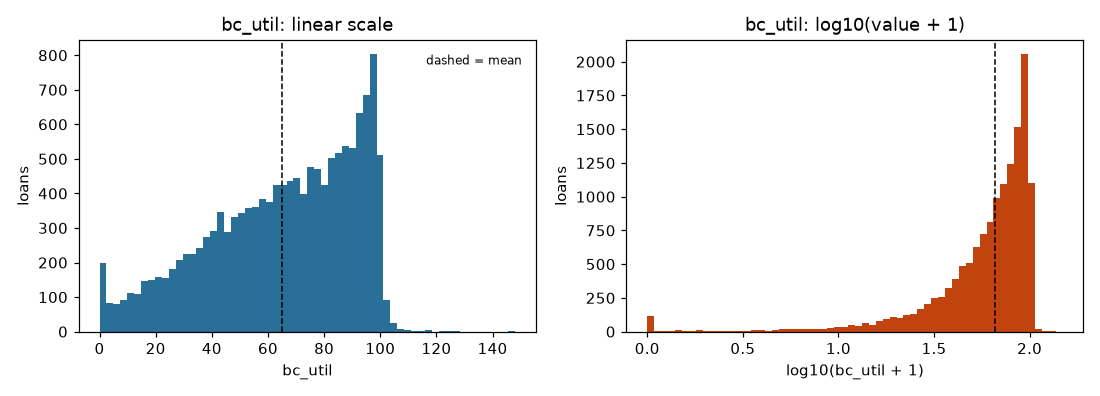

In [5]:
for f in MONEY + RATIOS:
    display(Image(f"reports/a2_financial_values_profile/figures/distribution_{f}.png", width=760))

## 2. Is mean ± 3 standard deviations a sound rule? (bullet 2)

We apply three rules to every field and count how many loans each flags. If a rule were sound, the three would roughly agree and the fences would sit in sensible places.

In [6]:
rows = []
for f in MONEY + RATIOS:
    s = fit[f].dropna()
    m, sd = s.mean(), s.std()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    med = s.median(); mad = (s - med).abs().median()
    rows.append({"field": f, "skew": round(s.skew(), 1),
                 "3std upper limit": round(m + 3 * sd, 1), "99th percentile": round(s.quantile(.99), 1), "3std lower limit": round(m - 3 * sd, 1),
                 "flagged by 3 std": int(((s > m + 3 * sd) | (s < m - 3 * sd)).sum()),
                 "flagged by IQR fences": int(((s > q3 + 1.5 * iqr) | (s < q1 - 1.5 * iqr)).sum()),
                 "flagged by robust z": int((0.6745 * (s - med).abs() / mad > 3).sum())})
rules = pd.DataFrame(rows)
print(rules.to_string(index=False))

           field  skew  3std upper limit  99th percentile  3std lower limit  flagged by 3 std  flagged by IQR fences  flagged by robust z
      annual_inc  63.3          305292.0         250000.0         -156543.4                57                    616                  654
       loan_amnt   0.7           39620.2          35000.0          -10348.7                 0                      0                    0
     installment   0.9            1184.0           1195.9            -294.4               168                    363                  393
       revol_bal   8.3           77207.7          88339.3          -44173.1               181                    715                  771
     tot_cur_bal   2.9          595363.1         631213.2         -317694.9               190                    428                 1088
     avg_cur_bal   4.8           61706.8          70493.7          -34813.1               239                    685                 1375
total_rev_hi_lim   5.7          12

**Reading it, field by field.**

| Field | Verdict | Why |
|---|---|---|
| `annual_inc` | **not sound** | One $7.5M income inflates the standard deviation, so the upper limit lands *above* the 99th percentile. The lower limit is negative. The three rules disagree wildly (about 57 / 616 / 654 flagged). |
| `revol_bal`, `tot_cur_bal`, `avg_cur_bal`, `total_rev_hi_lim`, `tot_hi_cred_lim` | **not sound** | Same pattern: the upper limit falls *below* the 99th percentile, so the rule flags ordinary heavy-tail borrowers, and the lower limit is negative. |
| `loan_amnt` | not needed | Bounded by the product (maximum $35,000-40,000); no tail to catch, and the rule flags nobody. |
| `installment` | works by accident | It is calculated from amount, rate and term, so it has no independent outliers. The rule flags 168 loans only because the field is bounded. |
| `dti`, `revol_util`, `bc_util` | sound but unnecessary | Nearly symmetric; the rule flags almost nobody. The meaningful limit is a business one (100% of the credit limit), so we simply cap them. |

**The general reason:** the rule assumes a symmetric bell shape, and money is not symmetric. A rule that relies on the standard deviation is wrecked by exactly the values it is supposed to catch. The IQR and robust-z rules do the opposite and flag thousands of genuine borrowers, so **none of the three is a trustworthy automatic threshold**.

## 3. Errors versus genuine extremes (bullet 3)

An **error** is impossible or a unit mistake: repair it. A **genuine extreme** is real but rare: keep it, and cap it so it cannot dominate. We judge only from information known at application time, **never from whether the loan defaulted**.

In [7]:
errors = pd.Series({
    "income typed in thousands": int(clean.annual_inc_fixed.sum()),
    "loan amount 10x too large": int(clean.loan_amnt_fixed.sum()),
    "revolving balance 10x too large": int(clean.revol_bal_fixed.sum()),
    "negative revol_util (sign flip)": int((joined.revol_util < 0).sum()),
    "negative bc_util (set to missing)": int(clean.bc_util_invalid.sum()),
})
extremes = pd.Series({
    "annual_inc above $1 million": int((clean.annual_inc > 1_000_000).sum()),
    "revol_util above 100%": int((clean.revol_util > 100).sum()),
    "bc_util above 100%": int((clean.bc_util > 100).sum()),
})
print("ERRORS (repaired in the cleaning step):\n" + errors.to_string())
print("\nGENUINE EXTREMES (kept, then capped):\n" + extremes.to_string())
print("\nThe five incomes above $1 million:")
print(clean[clean.annual_inc > 1_000_000][["annual_inc", "verification_status", "dti", "total_rev_hi_lim"]].to_string())

ERRORS (repaired in the cleaning step):
income typed in thousands            899
loan amount 10x too large            300
revolving balance 10x too large      308
negative revol_util (sign flip)      295
negative bc_util (set to missing)    290

GENUINE EXTREMES (kept, then capped):
annual_inc above $1 million      5
revol_util above 100%          116
bc_util above 100%             590

The five incomes above $1 million:
       annual_inc verification_status   dti  total_rev_hi_lim
817     7500000.0            Verified  0.20           36200.0
3415    1500000.0     Source Verified  1.19           52100.0
9747    1250000.0     Source Verified  1.82           18600.0
17707   1800000.0     Source Verified  2.83           48000.0
28052   5000000.0     Source Verified  0.43           81700.0


**Reading it.** The five million-dollar incomes were **verified or source-verified** by the platform and have tiny debt-to-income ratios, so we treat them as real and cap them rather than delete them. Utilisation above 100% is real too: a lender can cut a credit limit after the balance is already there. Compare that with `income = 53`, which is simply a unit mistake and gets repaired. **The test for an error is "impossible or contradicted by another field", not "large".**

## 4. Choosing a method, and what it does (bullet 4)

We compared nine treatments on three things: how symmetric the field becomes (skewness), how many rows are changed, and how well a simple model predicts default on later, unseen loans.

In [8]:
cmp = "reports/a2_outlier_method_comparison/tables/"
print("SKEWNESS after each treatment (closer to 0 is better):")
print(pd.read_csv(cmp + "skewness_after_treatment.csv").round(2).to_string(index=False))
print("\nPERCENT OF ROWS CHANGED:")
print(pd.read_csv(cmp + "rows_changed_pct.csv").round(2).to_string(index=False))
print("\nAUC of a simple model on later loans (with 95% interval):")
print(pd.read_csv(cmp + "auc_by_method.csv").round(3).to_string(index=False))

SKEWNESS after each treatment (closer to 0 is better):
           field  none  clip_mean_3std  clip_iqr_fences  clip_robust_z  winsor_p1_p99  winsor_p0.5_p99.5  log1p  log1p_winsor_p0.5_p99.5  log1p_clip_mean_3std
      annual_inc 63.33            2.09             0.91           0.87           1.76               2.07   0.21                     0.14                  0.12
       loan_amnt  0.71            0.71             0.71           0.71           0.71               0.71  -0.74                    -0.71                 -0.63
     installment  0.93            0.89             0.75           0.74           0.90               0.92  -0.68                    -0.63                 -0.55
       revol_bal  8.33            2.06             0.98           0.94           2.38               3.36  -2.46                    -0.82                 -0.50
     tot_cur_bal  2.89            1.32             1.10           0.80           1.38               1.54  -0.55                    -0.36              

**Reading it.**
- **Shape:** a cap alone (`winsor_p0.5_p99.5`) leaves `annual_inc` at skewness 2.1 and `revol_bal` at 3.4. The log alone leaves `revol_bal` at -2.5. **Cap first, then log** (`log1p_winsor_p0.5_p99.5`) gets every field to within 0.82 of zero.
- **Rows touched:** about 1% for the 0.5% / 99.5% cap, against roughly 2.5% to 10% for the IQR and robust-z rules, which cut genuine values.
- **Predictive power:** every method scores about 0.64 to 0.65 and the 95% intervals overlap, so accuracy **cannot separate** the methods. Using the money fields at all, however, helps: 0.586 without them against 0.64 to 0.65 with them (a gain of 0.05 to 0.06 AUC).
- **Choice:** *cap at the 0.5th and 99.5th percentile, then log(1 + x).* It gives the most symmetric shape, changes about 1% of rows, deletes nobody, and the limits are simple to store and explain. It was chosen on shape, rows touched and explainability, because predictive power was a tie.

Now the choice applied live to `annual_inc`, before and after.

annual_inc caps (fit window): lower $16,000, upper $300,000
skewness: raw 63.3 -> capped 2.1 -> capped then log 0.14


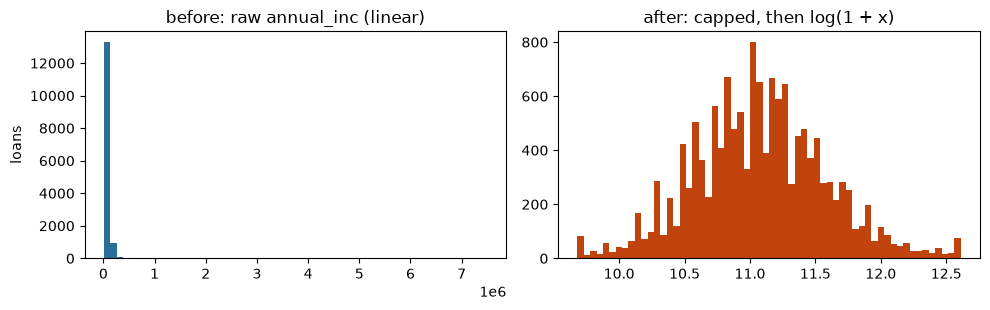

In [9]:
treater = AmountTreater().fit(clean)                      # learns the caps from the fit window only
treated = treater.transform(fit)
lo, hi = treater.caps_["annual_inc"]
print(f"annual_inc caps (fit window): lower ${lo:,.0f}, upper ${hi:,.0f}")
print(f"skewness: raw {fit.annual_inc.skew():.1f} -> capped {treated.annual_inc_capped.skew():.1f} -> capped then log {treated.annual_inc_log.skew():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(fit.annual_inc, bins=60, color="#2a6f97"); ax[0].set_title("before: raw annual_inc (linear)")
ax[1].hist(treated.annual_inc_log, bins=60, color="#c1440e"); ax[1].set_title("after: capped, then log(1 + x)")
ax[0].set_ylabel("loans"); fig.tight_layout(); plt.show()

### Default rate by decile, before and after

A **decile** cuts the loans into ten equal groups from lowest to highest value. If the treatment hid or scrambled risk, the default rate per decile would change.

    default_rate_before  default_rate_after  same
1                0.2102              0.2102  True
2                0.2175              0.2175  True
3                0.1785              0.1785  True
4                0.1833              0.1833  True
5                0.1799              0.1799  True
6                0.1685              0.1685  True
7                0.1671              0.1671  True
8                0.1556              0.1556  True
9                0.1252              0.1252  True
10               0.1385              0.1385  True


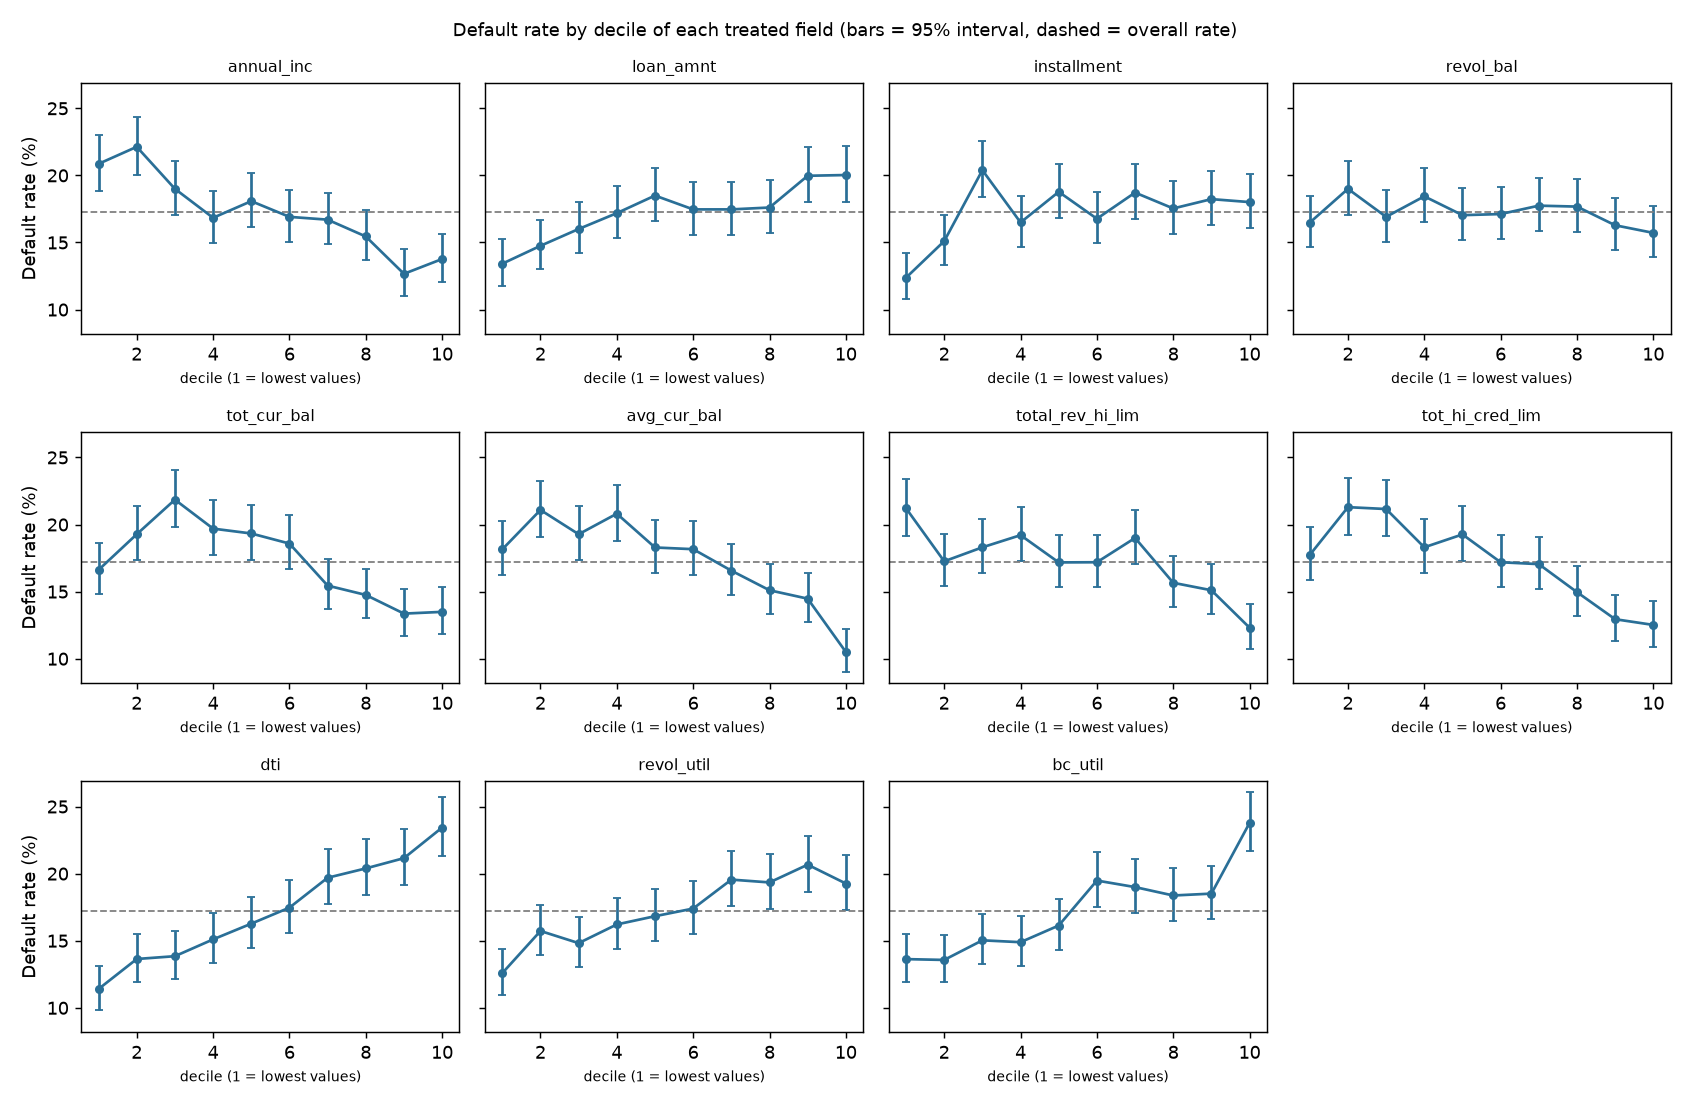

In [10]:
dec_before = pd.qcut(fit.annual_inc, 10, labels=False, duplicates="drop") + 1
dec_after = pd.qcut(treated.annual_inc_log, 10, labels=False, duplicates="drop") + 1
out = pd.DataFrame({"default_rate_before": fit.groupby(dec_before).defaulted.mean(),
                    "default_rate_after": treated.groupby(dec_after).defaulted.mean()}).round(4)
out["same"] = out.default_rate_before == out.default_rate_after
print(out.to_string())
display(Image("reports/a2_treatment_effect/figures/default_rate_by_decile.png", width=900))

**Reading it, honestly.** The two columns are identical **by construction**: capping and the log never change the *order* of loans, so a loan stays in the same decile. This shows that **nothing was lost**; it does *not* show a gain. The gain from treating the fields is the shape (skewness from 63 to near 0) and a calmer first principal component in notebook 05, where the biggest score falls from 11.5 to 3.6 standard deviations while the loadings barely change.

What the chart *does* show, with 95% intervals: higher income goes with a lower default rate, larger loans and higher `dti` with higher default.

## 5. Zero, negative and missing amounts (bullet 5)

Three different situations that look alike and must **not** be treated alike:

| Situation | Meaning | What we do |
|---|---|---|
| **Zero** | a real value (a person with no revolving balance) | keep it; add an `_is_zero` flag because the lower cap would lift a zero to the floor value |
| **Missing** | the value was never recorded | keep it missing; never turn it into zero; fill with a stated rule |
| **Negative** | impossible for an amount or a utilisation | repair if the sign flip is provable, else set to missing with a flag (notebook 01) |

In [11]:
summary = pd.DataFrame({
    "zeros (fit window)": [int((fit[f] == 0).sum()) for f in MONEY + RATIOS],
    "missing (fit window)": [int(fit[f].isna().sum()) for f in MONEY + RATIOS],
    "negatives (after cleaning)": [int((clean[f] < 0).sum()) for f in MONEY + RATIOS],
}, index=MONEY + RATIOS)
print(summary.to_string())
print("\nfields that get an _is_zero indicator:", treater.zero_fields_)
z = fit.revol_bal == 0
print(f"\nrevol_bal: {int(z.sum())} true zeros, default rate {fit.defaulted[z].mean():.1%} vs {fit.defaulted[~z].mean():.1%} for the rest")
print("\nHow to fill a missing ratio? Three rules compared on later loans (AUC with 95% interval):")
print(pd.read_csv("reports/a2_missing_amounts_experiment/tables/auc_by_fill_rule.csv").round(3).to_string(index=False))

                  zeros (fit window)  missing (fit window)  negatives (after cleaning)
annual_inc                         0                     0                           0
loan_amnt                          0                     0                           0
installment                        0                     0                           0
revol_bal                         40                     0                           0
tot_cur_bal                        3                     0                           0
avg_cur_bal                        3                     0                           0
total_rev_hi_lim                   2                     0                           0
tot_hi_cred_lim                    0                     0                           0
dti                                5                     0                           0
revol_util                        49                     4                           0
bc_util                          115       

**Reading it.** Missing values are rare in the fit window (only the utilisation ratios), and none of the three fill rules measurably beats the others, so we use the simplest: **fill with the fit-window median, and add a "was missing" flag only when at least 1% of values are missing**. The point of the table at the top is the *distinction*: a zero revolving balance is a fact about the person; a missing one is a gap in our knowledge. The 40 loans with a true zero balance default less often (10.0% against 17.3%), which is why a zero must stay a zero and not be filled; but with only 40 loans that gap is uncertain, so we don't build conclusions on it.

## 6. Fitted on the fit window only, and stored (bullet 6)

If we computed the caps on **all** loans, the 2015 loans would influence the rule used to judge 2015 loans, which is a form of leakage. So every cap comes from loans up to 31 Dec 2014, is frozen, and is applied unchanged to 2015 and to new applications.

In [12]:
caps = pd.DataFrame({
    "cap used (fit window p99.5)": {f: treater.caps_[f][1] for f in MONEY},
    "p99.5 if computed on all loans": {f: clean[f].quantile(0.995) for f in MONEY},
}).round(0)
caps["difference"] = (caps.iloc[:, 1] - caps.iloc[:, 0]).round(0)
print(caps.to_string())

spec = json.load(open("contract/data_spec.json"))
print("\nwhat the contract stores (data_spec.json):")
for f in spec["fields"]:
    if f["name"] in ("annual_inc", "revol_bal", "dti"):
        print(f"  {f['name']:12s} {f['cleaning']}")
print("\ntests that guard this rule:")
print(*[l for l in Path("tests/test_outliers.py").read_text().splitlines() if l.startswith("def test") and ("2015" in l or "caps" in l)], sep="\n")

                  cap used (fit window p99.5)  p99.5 if computed on all loans  difference
annual_inc                           300000.0                        300000.0         0.0
loan_amnt                             35000.0                         35000.0         0.0
installment                            1227.0                          1234.0         7.0
revol_bal                            126556.0                        130940.0      4384.0
tot_cur_bal                          755791.0                        757786.0      1995.0
avg_cur_bal                           85142.0                         85427.0       285.0
total_rev_hi_lim                     184670.0                        198833.0     14163.0
tot_hi_cred_lim                      869472.0                        869313.0      -159.0

what the contract stores (data_spec.json):
  annual_inc   values below 1,000 treated as thousands (x1000); capped at p0.5 = 16,000 and p99.5 = 300,000, then log(1 + x)
  dti          capped

**Reading it.** The difference column shows that for 6 of the 8 fields the cap *would* change if 2015 were allowed in (for example the revolving limit by about $14,000). The spec stores each field's rule in words and numbers (for example *"capped at p0.5 = 16,000 and p99.5 = 300,000, then log(1 + x)"*), so whoever scores a new application applies exactly the same limits. A test (`test_2015_loans_do_not_change_the_fitted_caps`) fails if 2015 data ever leaks into the fitting.

## Summary: what the brief asked, and where it is answered

| Brief bullet | Answered in |
|---|---|
| 1. Distribution profile, linear and log plots | section 1 (and `reports/a2_financial_values_profile/`) |
| 2. Is mean ± 3 std sound? | section 2 (verdict per field) |
| 3. Errors vs genuine extremes | section 3 |
| 4. Method choice, effect before and after, deciles | section 4 (and `reports/a2_outlier_method_comparison/`, `a2_treatment_effect/`) |
| 5. Zero, negative, missing | section 5 |
| 6. Fit window only, stored in the spec | section 6 |